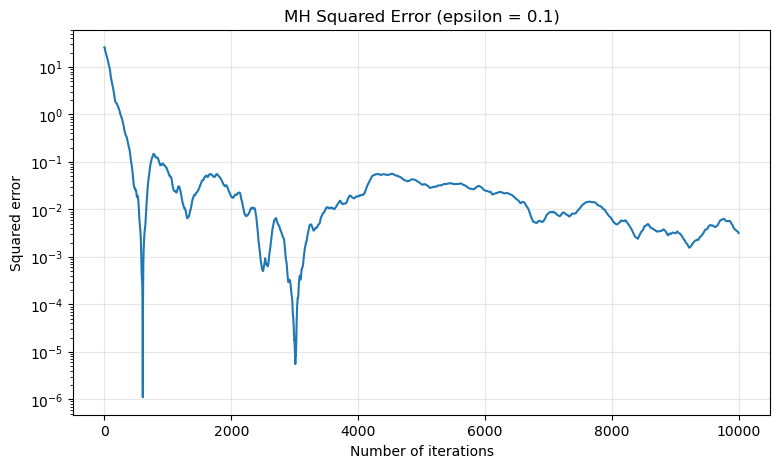

Final MC estimate: -0.056319426178995255
Acceptance rate: 0.7766


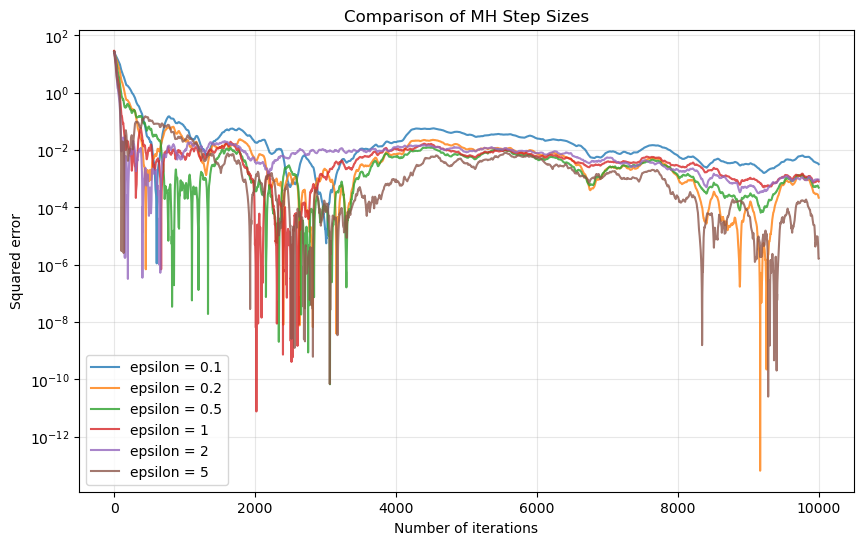

Epsilon    Acceptance Rate    Final Squared Error
0.1        0.7766             0.003172
0.2        0.6932             0.000216
0.5        0.5522             0.000484
1          0.4360             0.000792
2          0.3153             0.000910
5          0.1762             0.000002


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Target covariance matrix
Sigma = np.array([
    [1.0, 0.75],
    [0.75, 1.0]
])

Sigma_inv = np.linalg.inv(Sigma)

# Log target density (up to a constant)
def log_target(z):
    return -0.5 * z @ Sigma_inv @ z

def metropolis_hastings(epsilon, n_iter=10000, seed=42):
    rng = np.random.default_rng(seed)

    # Initial point
    z = np.array([5.0, 5.0])

    samples = np.zeros((n_iter, 2))
    accepted = 0

    for i in range(n_iter):
        # Step 1: Generate proposal
        proposal = z + np.sqrt(epsilon) * rng.normal(size=2)

        # Step 2: Compute log acceptance ratio
        log_alpha = log_target(proposal) - log_target(z)

        # Step 3: Accept or reject
        if np.log(rng.uniform()) < min(0.0, log_alpha):
            z = proposal
            accepted += 1

        samples[i] = z

    acceptance_rate = accepted / n_iter

    return samples, acceptance_rate

n_iter = 10000
epsilon = 0.1

samples, acceptance_rate = metropolis_hastings(
    epsilon=epsilon,
    n_iter=n_iter
)

# Extract the first coordinate
z1 = samples[:, 0]

# Running Monte Carlo mean
iterations = np.arange(1, n_iter + 1)
mc_estimates = np.cumsum(z1) / iterations

# True E[z1] = 0
squared_errors = mc_estimates**2

# Plot squared error
plt.figure(figsize=(9, 5))
plt.plot(iterations, squared_errors)

plt.xlabel("Number of iterations")
plt.ylabel("Squared error")
plt.title("MH Squared Error (epsilon = 0.1)")
plt.yscale("log")
plt.grid(alpha=0.3)
plt.show()

print("Final MC estimate:", mc_estimates[-1])
print("Acceptance rate:", acceptance_rate)

epsilons = [0.1, 0.2, 0.5, 1, 2, 5]

results = {}

plt.figure(figsize=(10, 6))

for eps in epsilons:
    samples, acceptance_rate = metropolis_hastings(
        epsilon=eps,
        n_iter=10000,
        seed=42
    )

    z1 = samples[:, 0]

    iterations = np.arange(1, 10001)
    mc_estimates = np.cumsum(z1) / iterations
    squared_errors = mc_estimates**2

    results[eps] = {
        "acceptance_rate": acceptance_rate,
        "final_estimate": mc_estimates[-1],
        "final_squared_error": squared_errors[-1]
    }

    plt.plot(
        iterations,
        squared_errors,
        label=f"epsilon = {eps}",
        alpha=0.8
    )

plt.xlabel("Number of iterations")
plt.ylabel("Squared error")
plt.title("Comparison of MH Step Sizes")
plt.yscale("log")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"{'Epsilon':<10} {'Acceptance Rate':<18} {'Final Squared Error'}")

for eps in epsilons:
    rate = results[eps]["acceptance_rate"]
    error = results[eps]["final_squared_error"]

    print(f"{eps:<10} {rate:<18.4f} {error:.6f}")

In [ ]:
%pip install arviz

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 805.0 kB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [arviz]32m3/5 [arviz_plots]
Note: you may need to restart the kernel to use updated packages.


(d) Estimated E[S]: -2.106
Theoretical E[S]: 0
      r_hat  ess_bulk
S  2.400247  4.985758
H  1.748910  6.130808


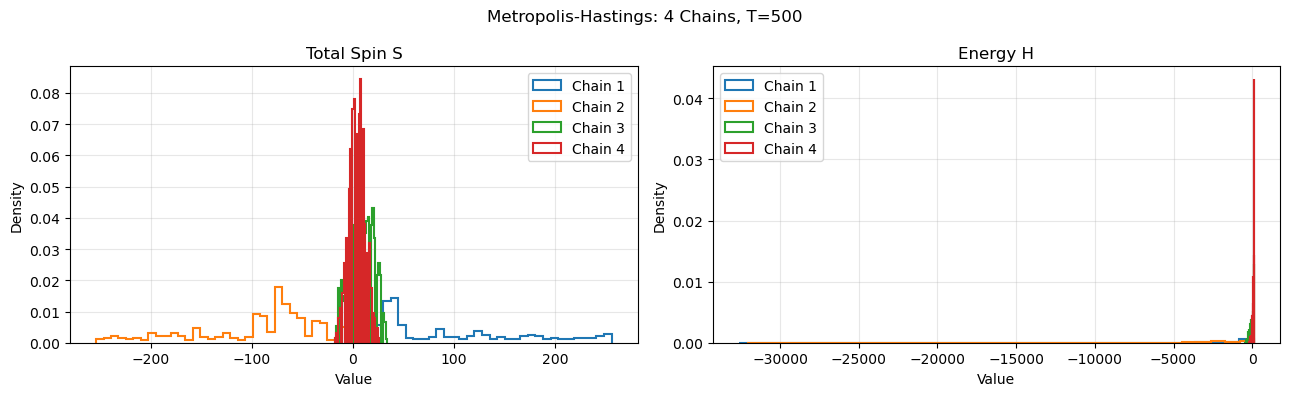


T = 1000
      r_hat   ess_bulk
S  1.540516   7.220156
H  1.304214  10.496401

T = 2000
      r_hat   ess_bulk
S  1.238818  12.013363
H  1.097118  28.057153

T = 4000
      r_hat   ess_bulk
S  1.087741  40.258583
H  1.033022  96.225741

T = 8000
      r_hat    ess_bulk
S  1.027893   72.351665
H  1.018386  174.178954

T = 16000
      r_hat    ess_bulk
S  1.021568  141.044314
H  1.007543  341.123560

T = 32000
      r_hat    ess_bulk
S  1.016586  323.256167
H  1.003935  799.893399

T = 64000
      r_hat     ess_bulk
S  1.008865   676.604103
H  1.002474  1716.850621

Final T: 64000
MH Estimated E[S]: 0.1030234375


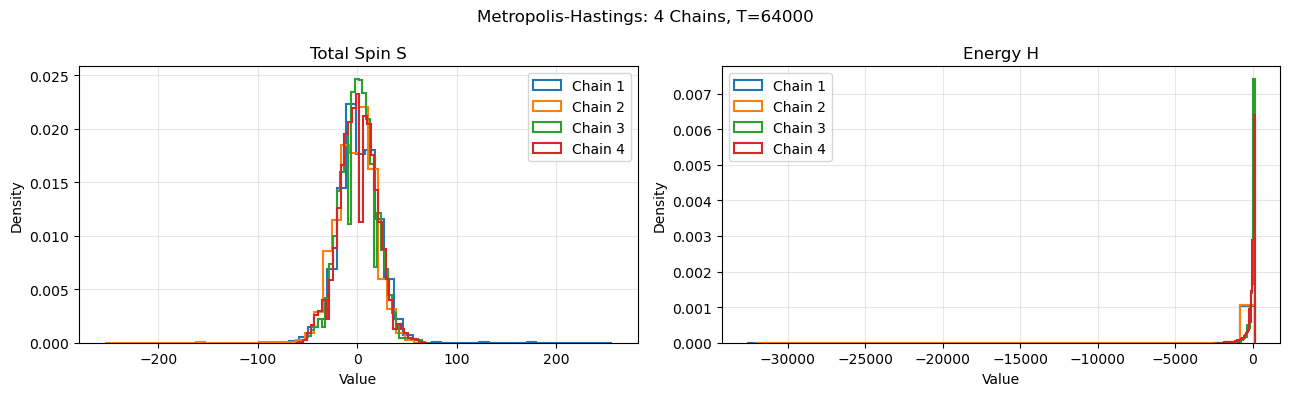


Gibbs Estimated E[S]: 0.1685234375
      r_hat    ess_bulk
S  1.004694  353.946674
H  1.004694  807.927441


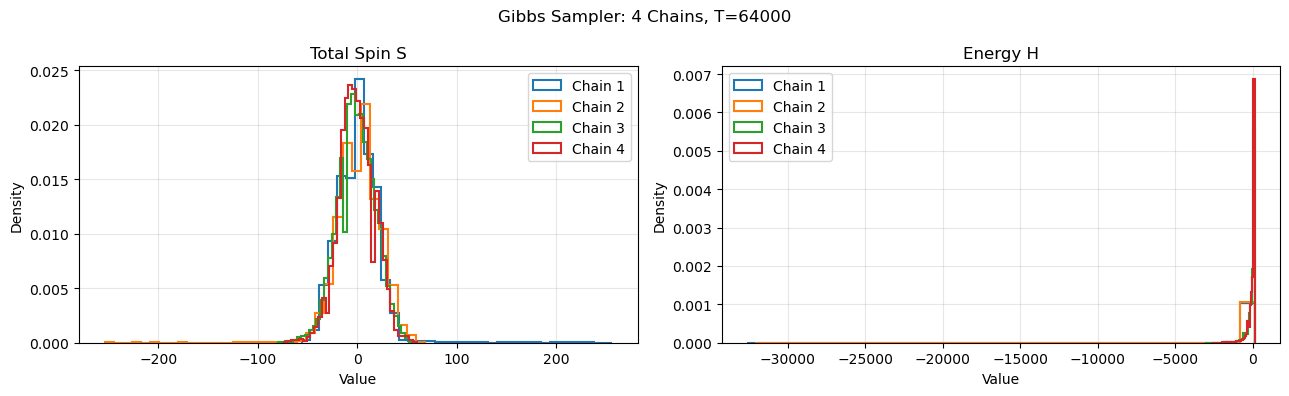


MH runtime: 0.6689021250058431
Gibbs runtime: 0.7144840839901008

ESS/s Comparison:
       MH ESS/s  Gibbs ESS/s
S  1011.514356   495.387765
H  2566.669407  1130.784378


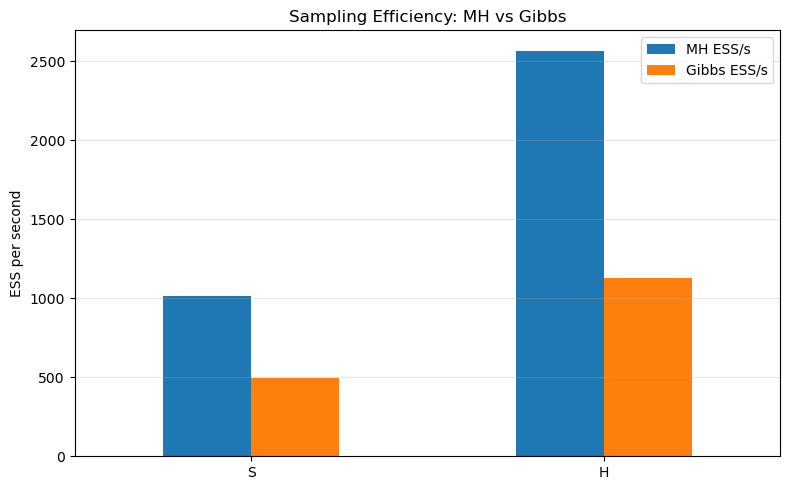

In [10]:

import numpy as np
import matplotlib.pyplot as plt
import arviz as az
import xarray as xr
import pandas as pd
import time

N = 256
beta = 1 / (4 * N)
n_chains = 4

def initial_state(c, rng):
    if c == 0:
        return np.ones(N, dtype=int)
    if c == 1:
        return -np.ones(N, dtype=int)
    if c == 2:
        return rng.choice([-1, 1], size=N)
    return np.array([1] * (N // 2) + [-1] * (N // 2))

def energy(S):
    return -0.5 * (S**2 - N)

def run_sampler(method, T, seed=42):
    S_chains = np.zeros((n_chains, T))
    H_chains = np.zeros((n_chains, T))
    start = time.perf_counter()

    for c in range(n_chains):
        rng = np.random.default_rng(seed + c)
        x = initial_state(c, rng)
        S = int(np.sum(x))

        for t in range(T):
            i = rng.integers(N)
            xi = x[i]
            h = S - xi

            if method == "MH":
                delta_H = 2 * xi * h
                if np.log(rng.random()) < min(0, -beta * delta_H):
                    x[i] = -xi
                    S -= 2 * xi
            elif method == "Gibbs":
                p_plus = 1 / (1 + np.exp(-2 * beta * h))
                new_xi = 1 if rng.random() < p_plus else -1
                x[i] = new_xi
                S += new_xi - xi
            else:
                raise ValueError("Invalid method")

            S_chains[c, t] = S
            H_chains[c, t] = energy(S)

    return S_chains, H_chains, time.perf_counter() - start

def diagnostics(S_chains, H_chains):
    S = xr.DataArray(S_chains, dims=("chain", "draw"))
    H = xr.DataArray(H_chains, dims=("chain", "draw"))

    return pd.DataFrame({
        "r_hat": [
            float(az.rhat(a, method="rank").item()) for a in (S, H)
        ],
        "ess_bulk": [
            float(az.ess(a, method="bulk").item()) for a in (S, H)
        ]
    }, index=["S", "H"])

def plot_densities(S_chains, H_chains, title):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    for c in range(n_chains):
        for ax, samples in zip(axes, (S_chains, H_chains)):
            ax.hist(samples[c], bins=35, density=True,
                    histtype="step", linewidth=1.5,
                    label=f"Chain {c + 1}")

    for ax, name in zip(axes, ("Total Spin S", "Energy H")):
        ax.set_title(name)
        ax.set_xlabel("Value")
        ax.set_ylabel("Density")
        ax.legend()
        ax.grid(alpha=0.3)

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

# (d)
S_mh, H_mh, time_mh = run_sampler("MH", 500)
print("(d) Estimated E[S]:", np.mean(S_mh))
print("Theoretical E[S]: 0")
print(diagnostics(S_mh, H_mh))
plot_densities(S_mh, H_mh, "Metropolis-Hastings: 4 Chains, T=500")

# (e)
T = 1000
while True:
    S_mh_long, H_mh_long, time_mh_long = run_sampler("MH", T)
    mh_summary = diagnostics(S_mh_long, H_mh_long)
    print(f"\nT = {T}\n{mh_summary}")

    if ((mh_summary["r_hat"] < 1.01).all()
            and (mh_summary["ess_bulk"] > 400).all()):
        break
    if T >= 128000:
        break
    T *= 2

print("\nFinal T:", T)
print("MH Estimated E[S]:", np.mean(S_mh_long))
plot_densities(S_mh_long, H_mh_long,
               f"Metropolis-Hastings: 4 Chains, T={T}")

# (f)
S_gibbs, H_gibbs, time_gibbs = run_sampler("Gibbs", T)
gibbs_summary = diagnostics(S_gibbs, H_gibbs)
print("\nGibbs Estimated E[S]:", np.mean(S_gibbs))
print(gibbs_summary)
plot_densities(S_gibbs, H_gibbs, f"Gibbs Sampler: 4 Chains, T={T}")

# (g)
comparison = pd.DataFrame({
    "MH ESS/s": mh_summary["ess_bulk"] / time_mh_long,
    "Gibbs ESS/s": gibbs_summary["ess_bulk"] / time_gibbs
})

print("\nMH runtime:", time_mh_long)
print("Gibbs runtime:", time_gibbs)
print("\nESS/s Comparison:\n", comparison)

comparison.plot(kind="bar", figsize=(8, 5))
plt.ylabel("ESS per second")
plt.title("Sampling Efficiency: MH vs Gibbs")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
